<a href="https://colab.research.google.com/github/turko-dev/DataScienceEntryLevel/blob/main/bpm_genders.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Difference in resting heart rate between men & women.

In [69]:
#imports
%matplotlib inline
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#init data
data = pd.read_csv("https://raw.githubusercontent.com/seanmb/teaching/refs/heads/main/runners_rhr_simulated.csv")

# Investigation

In [70]:
print(f"High: {data["Resting_HR_bpm"].max()} bpm")
print(f"Low: {data["Resting_HR_bpm"].min()} bpm")

High: 81 bpm
Low: 51 bpm


In [71]:
data = data.drop(columns=["Student_ID"])
data.head(1)

,Group,Age_years,Years_at_club,Last_competition_position,Last_competition_field_size,Resting_HR_bpm,Data_type
0,Men,30,3,54,84,54,Simulated


In [72]:
data.shape[0]

128

# Understanding the numerical data

In [73]:
data.groupby("Group", as_index=False)["Resting_HR_bpm"].describe()

,Group,count,mean,std,min,25%,50%,75%,max
0,Men,64.0,63.59375,6.243012,51.0,60.0,63.5,68.0,76.0
1,Women,64.0,65.59375,6.403666,52.0,61.0,65.5,70.0,81.0


In [74]:
#heart rate data of men
men = data[data["Group"] == "Men"]["Resting_HR_bpm"]

#heart rate data of women
women = data[data["Group"] == "Women"]["Resting_HR_bpm"]

In [75]:
#how skewed is the distribution of men's heart rates?
men_skew = men.skew()

In [76]:
#how skewed is the distribution of women's heart rates?
women_skew = women.skew()

# Plotting the distribution of men's vs women's heart rates
It looks quite similar at the moment, but we can't know for sure.

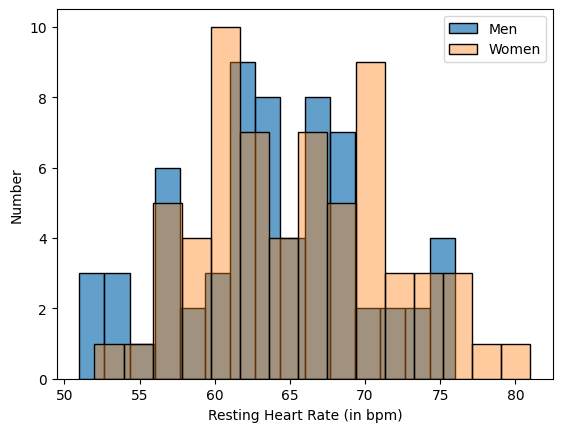

In [77]:

sns.histplot(men, alpha=0.7, bins=15, label="Men")
sns.histplot(women, alpha=0.4, bins=15, label="Women")

plt.xlabel("Resting Heart Rate (in bpm)")
plt.ylabel("Number")
plt.legend()
plt.show()

In [89]:
mean_difference = women.mean() - men.mean()

#T-Testing

In [90]:
import scipy.stats as stats
ttest = stats.ttest_ind(men, women, equal_var=True)
ci = ttest.confidence_interval()

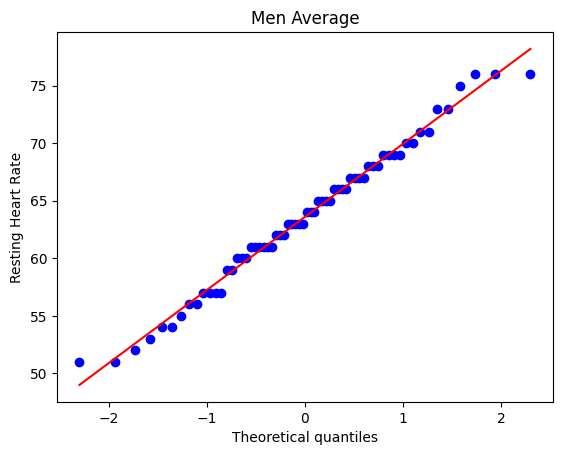

In [91]:
stats.probplot(men, dist="norm", plot=plt)
plt.title("Men Average")
plt.ylabel("Resting Heart Rate")
plt.show()

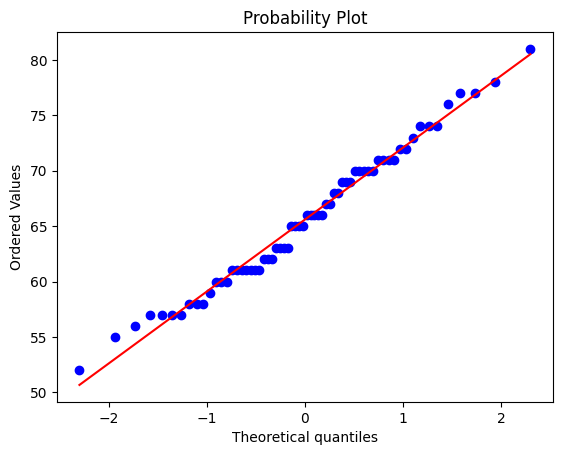

In [81]:
stats.probplot(women, dist="norm", plot=plt)
plt.show()

In [82]:
men_normality = stats.shapiro(men)
women_normality = stats.shapiro(women)

In [83]:
men_normality

ShapiroResult(statistic=np.float64(0.9830184585395393), pvalue=np.float64(0.5243330276807034))

In [84]:
women_normality

ShapiroResult(statistic=np.float64(0.9822714339538202), pvalue=np.float64(0.48719308973497033))

In [85]:
levene = stats.levene(men, women)

print(levene)

LeveneResult(statistic=np.float64(0.2410099464422341), pvalue=np.float64(0.6243315830060662))


# Results

# Normality Testing (Shapiro-Wilk Test) - P-Value
The p-value's we get from the Shapiro-Wilk test will determine if the distributions (men & women) have a normal distribution or not. This can help to inform a decision based on later data analysis.

A p-value higher than 0.05 will suggest that the dataset has a normal distribution.

The p-value we get as a result from both datasets are around 0.5.

In [86]:
print(f"Men's Normality P-Value: {round(men_normality.pvalue,2)}")
print(f"Women's Normality P-Value: {round(women_normality.pvalue,2)}")

Men's Normality P-Value: 0.52
Women's Normality P-Value: 0.49


# Equality of Variance (Levene Test) - P-Value
The p-value's that we get from the Levene test will suggest that the two distributions have equal variance. Again, going over 0.05 will suggest that the datasets are of equal variance. A p-value under 0.05 will suggest that the datasets have differing variance.

The p-value from the levene test is 0.62.

In [87]:
print(f"Levene Test P-Value: {round(levene.pvalue, 2)}")

Levene Test P-Value: 0.62


# Men & Women's Dataset Skew

Men's Skew (NO SKEW) -0.0193

Women's Skew (SLIGHT POSITIVE SKEW) 0.2153


In [88]:
print(f"Men's Dataset Skew: {round(men_skew, 4)} (NO SKEW)")
print(f"Women's Dataset Skew: {round(women_skew, 4)} (SLIGHT POSITIVE SKEW)")

Men's Dataset Skew: -0.0193 (NO SKEW)
Women's Dataset Skew: 0.2153 (SLIGHT POSITIVE SKEW)
